<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Keep the vector with the vulnerability score

**Do the returned vectors reproduce the published scores, and which records meet a chosen cutoff?**
We will retrieve three NVD records through the real VGI worker, recompute their
CVSS v3.1 base scores offline, and compare the metric values behind those scores.
SQL keeps missing records and unavailable metrics visible before applying a threshold.

The default uses **unmodified recorded NVD API responses**, served locally through
the worker's supported `base_url` option. This is a small teaching cohort of three
Log4j CVEs, not a current vulnerability inventory. Live mode is explicit and has no
fallback to recordings. Synthetic NULL/zero/version controls are shown separately.

## Choose the data mode and score cutoff

`DATA_MODE` is `"recorded"` by default; `"live"` requests the same three identifiers
from NVD. Live records can change and the API can rate-limit or fail. `SCORE_FLOOR`
is a finite number from 0 to 10, inclusive; the default is **9.0**, and the end
experiment lowers only this cutoff to **4.0**. Selection requires a returned v3.1
vector and a reported score at least the cutoff. Restart and run all after editing.
[Setup, capture provenance and live limitations](README.md).

In [1]:
DATA_MODE = "recorded"
SCORE_FLOOR = 9.0

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import math
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from notebook_support import finish, prose, theme
from nvd_replay import NVDSource

if (
    isinstance(SCORE_FLOOR, bool)
    or not isinstance(SCORE_FLOOR, (int, float))
    or not math.isfinite(SCORE_FLOOR)
    or not 0 <= SCORE_FLOOR <= 10
):
    raise ValueError("SCORE_FLOOR must be a finite number from 0 through 10.")
source = NVDSource(DATA_MODE)
NVD_BASE_URL = source.base_url
capture_date = (
    source.manifest["records"][0]["captured_at_utc"] if source.manifest else source.started_at
)[:10]
SOURCE_LABEL = f"Source: {DATA_MODE.title()} NVD ({capture_date} UTC) · VGI cve v0.4.0 · CVSS v3.1"
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/vgi-cve/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/vgi-cve/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/vgi-cve/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-cve/notebooks/pyproject.toml.

In [4]:
prose(
    f"**{source.provenance}.** "
    + (
        "The local endpoint serves only the three recorded CVE-ID requests and checks their SHA-256 digests."
        if DATA_MODE == "recorded"
        else "These are separate live requests, not an atomic NVD snapshot; failures remain errors."
    )
)

**Recorded NVD responses captured 2026-11-14T06:05:01.542551+00:00 through 2026-11-14T06:09:32.099758+00:00.** The local endpoint serves only the three recorded CVE-ID requests and checks their SHA-256 digests.

## Connect to the released worker

The literal `github-auto` location downloads and verifies the native release.
Only the NVD data endpoint changes with data mode; the worker binary is identical.
The small offline query confirms that a numeric zero severity and a missing score
remain distinct before any API data is retrieved.

In [5]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'cve' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-cve@v0.4.0');
SELECT cve.main.cvss_severity(0.0) AS zero_severity,
       cve.main.cvss_severity(NULL::DOUBLE) AS missing_severity;

,zero_severity,missing_severity
0,NONE,None


## Fetch once, then analyze the materialized records

Each table-function call receives a constant CVE identifier. Materialize before
capturing a DataFrame so display does not repeat requests. The worker prefers the
**first v3.1 metric**, then the first v3.0 metric, then v2; it does not aggregate
multiple assessments. Keep its returned vector and source timestamps alongside
the score. The raw recordings retain the complete response and metric provenance.

We recompute only explicit v3.1 vectors here. Missing and other-version metrics
remain labelled instead of being sent to an incompatible scoring formula.

In [6]:
%%sql
CREATE OR REPLACE TABLE cohort AS SELECT * FROM (VALUES
 ('CVE-2021-44228'),('CVE-2021-45046'),('CVE-2021-45105')) AS t(requested_id);
CREATE OR REPLACE TABLE returned AS
SELECT * FROM cve.main.cve('CVE-2021-44228',base_url := '{{ NVD_BASE_URL }}')
UNION ALL
SELECT * FROM cve.main.cve('CVE-2021-45046',base_url := '{{ NVD_BASE_URL }}')
UNION ALL
SELECT * FROM cve.main.cve('CVE-2021-45105',base_url := '{{ NVD_BASE_URL }}');
CREATE OR REPLACE TABLE compared AS
SELECT requested_id AS id, r.id IS NOT NULL AS record_returned,
 cvss_score AS reported_score, cvss_severity AS reported_severity, cvss_vector,
 published, last_modified,
 CASE WHEN r.id IS NULL THEN 'Not returned'
      WHEN cvss_score IS NULL OR cvss_vector IS NULL THEN 'Metric unavailable'
      WHEN NOT starts_with(cvss_vector,'CVSS:3.1/') THEN 'Other CVSS version'
      ELSE 'Comparable v3.1' END AS availability,
 CASE WHEN starts_with(cvss_vector,'CVSS:3.1/')
      THEN cve.main.cvss_base_score(cvss_vector) END AS recomputed_score
FROM cohort LEFT JOIN returned r ON r.id=cohort.requested_id;
SELECT id, reported_score, reported_severity, cvss_vector, availability,
 published, last_modified FROM compared ORDER BY id;

,id,reported_score,reported_severity,cvss_vector,availability,published,last_modified
0,CVE-2021-44228,10.0,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:C/C:H/I:H/A:H,Comparable v3.1,2021-12-10T10:15:09.143,2026-08-11T19:33:44.513
1,CVE-2021-45046,9.0,CRITICAL,CVSS:3.1/AV:N/AC:H/PR:N/UI:N/S:C/C:H/I:H/A:H,Comparable v3.1,2021-12-14T19:15:07.733,2026-06-17T04:13:05.570
2,CVE-2021-45105,5.9,MEDIUM,CVSS:3.1/AV:N/AC:H/PR:N/UI:N/S:U/C:N/I:N/A:H,Comparable v3.1,2021-12-18T12:15:07.433,2026-08-25T16:28:27.310


In [7]:
%%sql scores <<
SELECT *, recomputed_score-reported_score AS score_difference,
 cve.main.cvss_severity(recomputed_score) AS recomputed_severity,
 CASE WHEN availability='Comparable v3.1' THEN reported_score >= {{ SCORE_FLOOR }}
      ELSE NULL END AS selected
FROM compared ORDER BY reported_score DESC NULLS LAST,id;

In [8]:
scores = globals()["scores"]
display(
    scores[
        ["id", "availability", "reported_score", "recomputed_score", "score_difference", "selected"]
    ]
)
if DATA_MODE == "recorded":
    expected_ids = set(scores.id)
    assert set(source.requests) == expected_ids and all(n == 1 for n in source.requests.values()), (
        source.requests
    )
    prose(
        f"The request audit confirms **{sum(source.requests.values())} API requests**, one per recorded identifier. "
        "All following calculations use the materialized table."
    )
comparable = scores[scores.availability == "Comparable v3.1"]
agreements = int((comparable.score_difference.abs() < 1e-9).sum())
prose(
    f"**{len(comparable)} of {len(scores)} requested records** have comparable v3.1 metrics. "
    f"**{agreements}** reproduce the returned score exactly to one decimal place. "
    "Any mismatch remains visible for review; a score alone does not retain the underlying assessment."
)

,id,availability,reported_score,recomputed_score,score_difference,selected
0,CVE-2021-44228,Comparable v3.1,10.0,10.0,0.0,True
1,CVE-2021-45046,Comparable v3.1,9.0,9.0,0.0,True
2,CVE-2021-45105,Comparable v3.1,5.9,5.9,0.0,False


The request audit confirms **3 API requests**, one per recorded identifier. All following calculations use the materialized table.

**3 of 3 requested records** have comparable v3.1 metrics. **3** reproduce the returned score exactly to one decimal place. Any mismatch remains visible for review; a score alone does not retain the underlying assessment.

## Compare scores on a shared scale

Filled circles show the reported score; hollow diamonds show offline recomputation.
The vertical line is the chosen cutoff. Unavailable scores are labelled in the row
instead of drawn at zero. CVSS base scores describe vulnerability characteristics;
they do not incorporate this reader's asset exposure or business context. See the
[FIRST CVSS v3.1 specification](https://www.first.org/cvss/v3.1/specification-document).

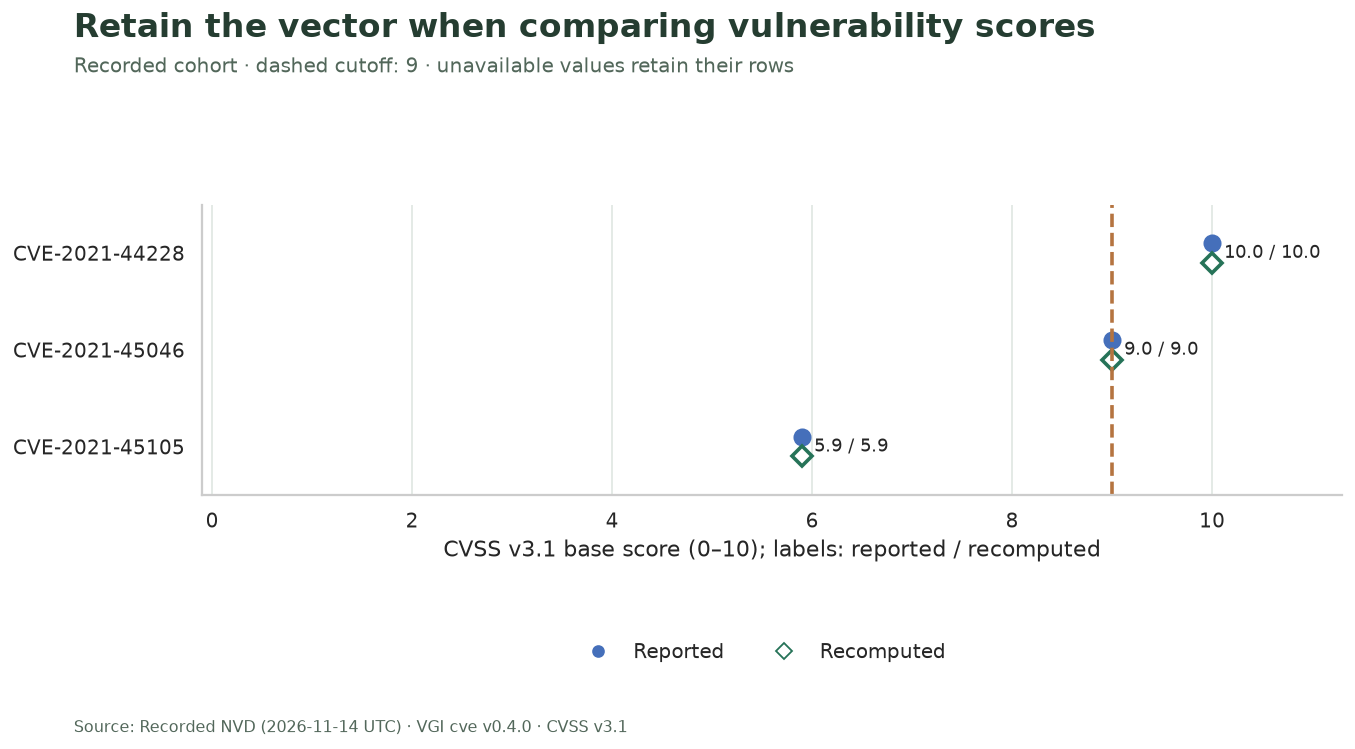

In [9]:
fig, ax = plt.subplots(figsize=(10.8, 5.8))
for y, row in enumerate(scores.itertuples(index=False)):
    if row.availability == "Comparable v3.1":
        ax.plot(row.reported_score, y - 0.10, "o", color="#456fba", markersize=9)
        ax.plot(
            row.recomputed_score,
            y + 0.10,
            "D",
            markerfacecolor="white",
            markeredgecolor="#267358",
            markeredgewidth=2,
            markersize=8,
        )
        ax.text(
            max(row.reported_score, row.recomputed_score) + 0.12,
            y,
            f"{row.reported_score:.1f} / {row.recomputed_score:.1f}",
            va="center",
            fontsize=10,
        )
    else:
        ax.text(0.15, y, row.availability, va="center", color="#786b60")
ax.axvline(SCORE_FLOOR, color="#b57440", linestyle="--", linewidth=2)
ax.set_yticks(np.arange(len(scores)), scores.id)
ax.set_ylim(len(scores) - 0.5, -0.5)
ax.set_xlim(-0.1, 11.3)
ax.set_xticks(np.arange(0, 11, 2))
ax.set_xlabel("CVSS v3.1 base score (0–10); labels: reported / recomputed")
ax.grid(axis="y", visible=False)
fig.legend(
    handles=[
        plt.Line2D([], [], marker="o", linestyle="none", color="#456fba", label="Reported"),
        plt.Line2D(
            [],
            [],
            marker="D",
            linestyle="none",
            markerfacecolor="white",
            markeredgecolor="#267358",
            label="Recomputed",
        ),
    ],
    loc="center",
    bbox_to_anchor=(0.57, 0.13),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Retain the vector when comparing vulnerability scores",
    f"{DATA_MODE.title()} cohort · dashed cutoff: {SCORE_FLOOR:g} · unavailable values retain their rows",
    f"scores-{DATA_MODE}-{SCORE_FLOOR:g}.png",
    bottom=0.22,
    source=SOURCE_LABEL,
)

## Look inside the vector

The matrix extracts the eight base metric values from each returned v3.1 vector.
Amber marks a metric column whose values differ within this cohort; it is **not**
a severity scale. Green outlines identify records meeting the chosen cutoff.

AV = attack vector; AC = attack complexity; PR = privileges required; UI = user
interaction; S = scope; C/I/A = confidentiality, integrity and availability impact.
The letters are the original vector tokens, not numerical weights. The complete
vectors remain in the earlier SQL table.

In [10]:
%%sql metric_rows <<
SELECT id, ordinal, metric,
 CASE WHEN availability='Comparable v3.1'
      THEN regexp_extract(cvss_vector,'(?:^|/)' || metric || ':([^/]+)',1)
      ELSE NULL END AS metric_value
FROM compared CROSS JOIN (VALUES
 (1,'AV'),(2,'AC'),(3,'PR'),(4,'UI'),(5,'S'),(6,'C'),(7,'I'),(8,'A')) AS m(ordinal,metric)
ORDER BY id,ordinal;

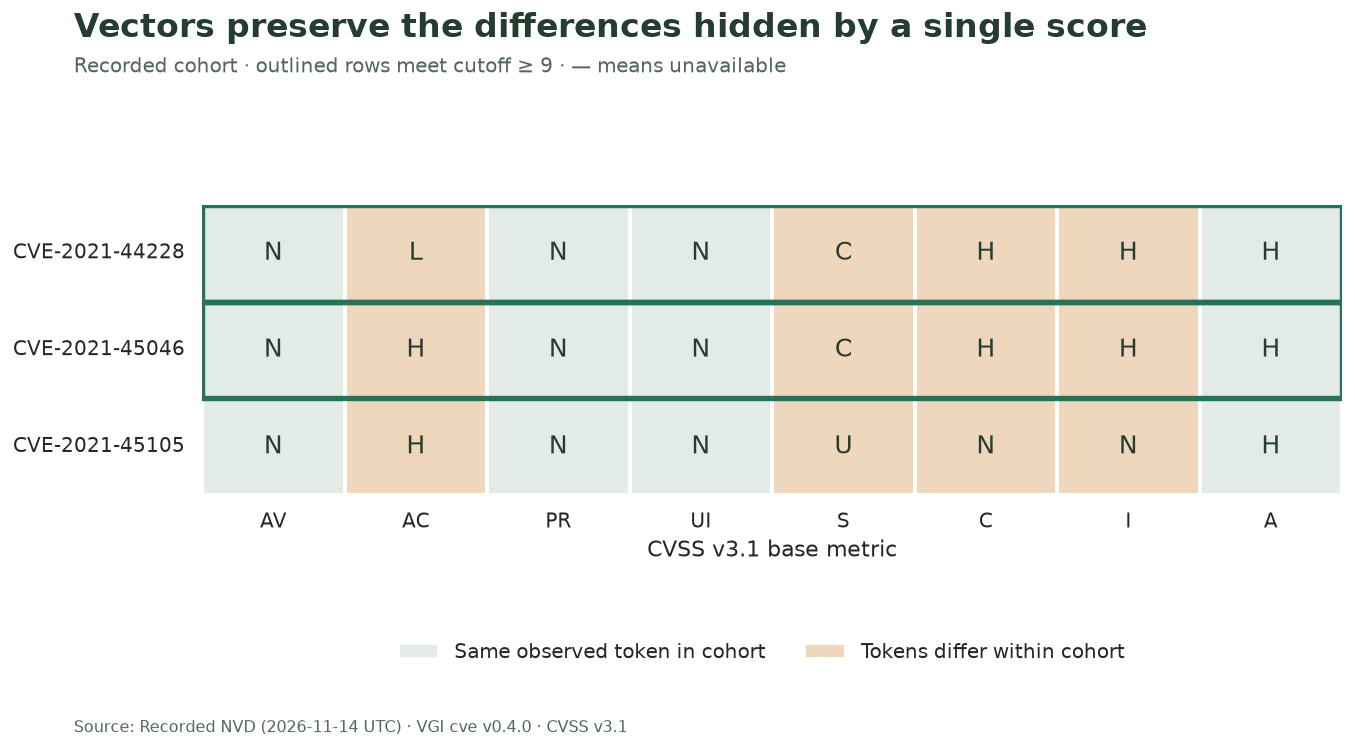

At **9**, **2 of 3 requested records** enter the score-based queue: CVE-2021-44228, CVE-2021-45046. **0** lack comparable v3.1 metrics and remain outside that numeric selection with their availability labels intact. This cohort is illustrative, not a complete product assessment.

In [11]:
metric_rows = globals()["metric_rows"]
metrics = ["AV", "AC", "PR", "UI", "S", "C", "I", "A"]
matrix = metric_rows.pivot(index="id", columns="metric", values="metric_value").reindex(
    index=scores.id, columns=metrics
)
varies = matrix.nunique(dropna=True) > 1
background = np.tile(varies.to_numpy(dtype=int), (len(matrix), 1))
fig, ax = plt.subplots(figsize=(10.8, 5.8))
sns.heatmap(
    background,
    annot=matrix.fillna("—"),
    fmt="",
    cmap=ListedColormap(["#e2ebe6", "#efd7bd"]),
    vmin=-0.5,
    vmax=1.5,
    cbar=False,
    linewidths=2,
    linecolor="white",
    ax=ax,
    annot_kws={"fontsize": 14, "color": "#253d31"},
)
ax.set_xticklabels(metrics, rotation=0)
ax.set_yticklabels(matrix.index, rotation=0)
ax.set_xlabel("CVSS v3.1 base metric")
ax.set_ylabel("")
for y, row in enumerate(scores.itertuples(index=False)):
    if row.availability == "Comparable v3.1" and bool(row.selected):
        ax.add_patch(
            Rectangle((0, y), len(metrics), 1, fill=False, edgecolor="#267358", linewidth=3)
        )
fig.legend(
    handles=[
        Patch(facecolor="#e2ebe6", label="Same observed token in cohort"),
        Patch(facecolor="#efd7bd", label="Tokens differ within cohort"),
    ],
    loc="center",
    bbox_to_anchor=(0.57, 0.13),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Vectors preserve the differences hidden by a single score",
    f"{DATA_MODE.title()} cohort · outlined rows meet cutoff ≥ {SCORE_FLOOR:g} · — means unavailable",
    f"metric-matrix-{DATA_MODE}-{SCORE_FLOOR:g}.png",
    bottom=0.22,
    source=SOURCE_LABEL,
)
selected_ids = scores.loc[scores.selected.fillna(False).astype(bool), "id"].tolist()
prose(
    f"At **{SCORE_FLOOR:g}**, **{len(selected_ids)} of {len(scores)} requested records** enter the score-based queue: "
    + (", ".join(selected_ids) if selected_ids else "none")
    + f". **{int((scores.availability != 'Comparable v3.1').sum())}** lack comparable v3.1 metrics and remain outside "
    "that numeric selection with their availability labels intact. This cohort is illustrative, not a complete product assessment."
)

## Keep missing, zero and unsupported versions separate

These three **synthetic controls are not NVD records**. A NULL vector should yield
NULL score and severity. A valid zero-impact v3.1 vector yields a real zero and
`NONE`. A v2 vector is kept outside this v3.1 recomputation path instead of being
interpreted under a different scoring system.

In [12]:
%%sql
CREATE OR REPLACE TABLE controls AS
SELECT * FROM (VALUES
 ('Missing vector',NULL::VARCHAR),
 ('Zero-impact v3.1','CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:N/I:N/A:N'),
 ('v2 outside this comparison','AV:N/AC:L/Au:N/C:P/I:P/A:P')) AS t(label,vector);
CREATE OR REPLACE TABLE control_results AS
SELECT *, CASE WHEN vector IS NULL OR starts_with(vector,'CVSS:3.1/')
 THEN cve.main.cvss_base_score(vector) END AS base_score FROM controls;
SELECT label,vector,base_score,cve.main.cvss_severity(base_score) AS severity FROM control_results;

,label,vector,base_score,severity
0,Missing vector,None,NaN,None
1,Zero-impact v3.1,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:N/I:N/A:N,0.0,NONE
2,v2 outside this comparison,AV:N/AC:L/Au:N/C:P/I:P/A:P,NaN,None


## Validate the data contract

Check unique requested records, bounded scores, explicit version filtering and the
NULL/zero controls. Reported/recomputed differences remain evidence in the comparison
table; these checks do not require changing upstream data to match an expected ranking.

In [13]:
%%sql checks <<
SELECT 'Requested identifiers remain represented once' AS check_name,
 abs((SELECT count(*) FROM cohort)-(SELECT count(*) FROM compared))
 + (SELECT count(*)-count(DISTINCT id) FROM compared) AS violations
UNION ALL
SELECT 'API records have no duplicate or unexpected identifiers',
 count(*)-count(DISTINCT id) + count(*) FILTER (WHERE id NOT IN (SELECT requested_id FROM cohort)) FROM returned
UNION ALL
SELECT 'Available scores are finite and bounded',count(*) FROM compared
WHERE (reported_score IS NOT NULL AND (NOT isfinite(reported_score) OR reported_score<0 OR reported_score>10))
 OR (recomputed_score IS NOT NULL AND (NOT isfinite(recomputed_score) OR recomputed_score<0 OR recomputed_score>10))
UNION ALL
SELECT 'Other or unavailable vectors are not recomputed',count(*) FROM compared
WHERE (cvss_vector IS NULL OR NOT starts_with(cvss_vector,'CVSS:3.1/')) AND recomputed_score IS NOT NULL
UNION ALL
SELECT 'Missing vector retains missing score and severity',count(*) FROM control_results
WHERE vector IS NULL AND (base_score IS NOT NULL OR cve.main.cvss_severity(base_score) IS NOT NULL)
UNION ALL
SELECT 'Zero-impact control is a real zero with NONE severity',count(*) FROM control_results
WHERE label='Zero-impact v3.1' AND (base_score IS DISTINCT FROM 0.0 OR cve.main.cvss_severity(base_score) IS DISTINCT FROM 'NONE')
UNION ALL
SELECT 'v2 control remains outside v3.1 scoring',count(*) FROM control_results
WHERE label='v2 outside this comparison' AND base_score IS NOT NULL;

In [14]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), "A CVE data-contract check failed."
prose(
    f"All **{len(checks)} contract checks** pass. Offline recomputation verifies the returned "
    "base vector's arithmetic; it does not establish whether the vector captures an asset's exposure."
)

,check_name,violations
0,Requested identifiers remain represented once,0
1,API records have no duplicate or unexpected id...,0
2,Available scores are finite and bounded,0
3,Other or unavailable vectors are not recomputed,0
4,Missing vector retains missing score and severity,0
5,Zero-impact control is a real zero with NONE s...,0
6,v2 control remains outside v3.1 scoring,0


All **7 contract checks** pass. Offline recomputation verifies the returned base vector's arithmetic; it does not establish whether the vector captures an asset's exposure.

## One change to try

Keep `DATA_MODE = "recorded"`, lower `SCORE_FLOOR` from **9.0** to **4.0**, and run all.
Predict which outlined rows will change. Compare the selected-ID list and cutoff line;
the returned vectors, scores, source timestamps and recomputation should stay identical.
Reset to **9.0** afterward.

```sh
uv run --locked python execute.py --parameters '{"SCORE_FLOOR":4.0}' \
  --output-dir validation/floor-4
```

Live mode is a separate test, not part of that controlled experiment:

```sh
uv run --locked python execute.py --parameters '{"DATA_MODE":"live"}' \
  --output-dir validation/live
```

The worker also offers bounded keyword and CPE searches. Those results require their
own coverage checks; this fixed three-ID example makes no claim about a complete
vulnerability set or remediation priority. NVD responses are courtesy of NIST/NVD;
this example is not endorsed by NIST.

In [15]:
con.close()
source.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)